# Customer Churn Analysis

## 1. Project Setup

### 1.1 Import Required Libraries

In [1]:
# Import required libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

# Ignore unnecessary warnings
warnings.filterwarnings('ignore')

# Set a clean visual style
sns.set_theme(style='whitegrid')

print("Everything is ready!")

Everything is ready!


## 2. Load Dataset

### 2.1 Load Excel Sheets

In [2]:
# Define the path of the churn dataset
file_path = r"C:\Users\rg747\churn\customer_churn_data.xlsx"

# Load all three sheets into separate DataFrames
df_customer = pd.read_excel(file_path, sheet_name='db_customer')
df_subscription = pd.read_excel(file_path, sheet_name='db_subscription')
df_support = pd.read_excel(file_path, sheet_name='db_support')

print("✅ All sheets loaded successfully!")
print(f"Customer table     : {df_customer.shape[0]:,} rows, {df_customer.shape[1]} columns")
print(f"Subscription table : {df_subscription.shape[0]:,} rows, {df_subscription.shape[1]} columns")
print(f"Support table      : {df_support.shape[0]:,} rows, {df_support.shape[1]} columns")

✅ All sheets loaded successfully!
Customer table     : 10,000 rows, 8 columns
Subscription table : 10,000 rows, 11 columns
Support table      : 4,647 rows, 6 columns


### 2.2 Preview Each Table

In [3]:
# Preview Customer table
print("Customer Table Preview:")
display(df_customer.head())

# Preview Subscription table
print("\nSubscription Table Preview:")
display(df_subscription.head())

# Preview Support table
print("\nSupport Table Preview:")
display(df_support.head())

Customer Table Preview:


,customerid,name,country,state,gender,dob,interests,pincode
0,0001-QAHFT,jatin gupta,NaN,Maharashtra,Male,1976-06-04,travel,NaN
1,0002-CGPOS,poonam yadav,India,Haryana,Female,1984-11-20,cooking,NaN
2,0003-PVAUS,tushar jain,India,Meghalaya,Male,1984-08-28,music,NaN
3,0004-CJJIG,sai trivedi,Nepal,Kathmandu,Male,1995-08-11,NaN,NaN
4,0005-DXCHQ,garima banerjee,India,Jharkhand,Female,1983-08-17,NaN,NaN



Subscription Table Preview:


,customerid,subscription_start_date,subscription_type,renewal_date,plan_type,contract_type,cancellation_date,cancellation_reason,monthly_charges,cltv,churn_score
0,0001-QAHFT,2021-12-13,Refferal,2023-08-30,Basic,Annual,2022-05-05,Switched to competitor,10.36,1129,81
1,0002-CGPOS,2019-12-03,Paid,2021-05-25,Standard,Monthly,NaN,NaN,18.28,1608,25
2,0003-PVAUS,2024-12-13,Organic,2027-11-27,Premium,Monthly,NaN,NaN,33.61,1075,35
3,0004-CJJIG,2021-04-11,Refferal,2023-02-18,Standard,Annual,NaN,NaN,16.50,1815,11
4,0005-DXCHQ,2021-02-27,Refferal,2023-02-27,Standard,Monthly,NaN,NaN,19.36,348,4



Support Table Preview:


,customerid,complaint_date,escalations,csat_score,col_1,comment
0,0571-EHXRX,2025-08-28,N,37,NaN,demaned refund
1,3031-BJATU,2025-11-16,Y,16,NaN,service issue
2,4728-YZTRN,2023-02-23,N,32,NaN,billing problem
3,8877-JTZPQ,2023-08-27,N,35,NaN,app crash
4,4920-SOKJC,2024-12-09,Y,23,NaN,received refund


## 3. Data Understanding

### 3.1 Shape & Basic Info

In [4]:
# Check basic information of all three tables
print("===== CUSTOMER TABLE =====")
print(df_customer.info())
print("\n")

print("===== SUBSCRIPTION TABLE =====")
print(df_subscription.info())
print("\n")

print("===== SUPPORT TABLE =====")
print(df_support.info())

===== CUSTOMER TABLE =====
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   customerid  10000 non-null  str    
 1   name        10000 non-null  str    
 2   country     9306 non-null   str    
 3   state       10000 non-null  str    
 4   gender      10000 non-null  str    
 5   dob         10000 non-null  str    
 6   interests   6629 non-null   str    
 7   pincode     0 non-null      float64
dtypes: float64(1), str(7)
memory usage: 625.1 KB
None


===== SUBSCRIPTION TABLE =====
<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customerid               10000 non-null  str    
 1   subscription_start_date  10000 non-null  str    
 2   subscription_type        10000 non-null  str    
 3   renewal

### 3.2 Missing Values Check

In [5]:
# Check missing values in each table
print("Missing Values - Customer Table:")
print(df_customer.isnull().sum())
print("\n")

print("Missing Values - Subscription Table:")
print(df_subscription.isnull().sum())
print("\n")

print("Missing Values - Support Table:")
print(df_support.isnull().sum())

Missing Values - Customer Table:
customerid        0
name              0
country         694
state             0
gender            0
dob               0
interests      3371
pincode       10000
dtype: int64


Missing Values - Subscription Table:
customerid                    0
subscription_start_date       0
subscription_type             0
renewal_date                  0
plan_type                     0
contract_type                 0
cancellation_date          7273
cancellation_reason        7273
monthly_charges               0
cltv                          0
churn_score                   0
dtype: int64


Missing Values - Support Table:
customerid           0
complaint_date       0
escalations          0
csat_score           0
col_1             4647
comment            977
dtype: int64


### 3.3 Unique Values & Key Columns Check

In [6]:
# Check unique customer IDs in each table
print("Unique Customer IDs:")
print(f"Customer table     : {df_customer['customerid'].nunique()}")
print(f"Subscription table : {df_subscription['customerid'].nunique()}")
print(f"Support table      : {df_support['customerid'].nunique()}")

print("\n")

# Check key categorical columns in Subscription table
print("Plan Type unique values:")
print(df_subscription['plan_type'].unique())

print("\nSubscription Type unique values:")
print(df_subscription['subscription_type'].unique())

print("\nContract Type unique values:")
print(df_subscription['contract_type'].unique())

Unique Customer IDs:
Customer table     : 10000
Subscription table : 10000
Support table      : 3800


Plan Type unique values:
<StringArray>
['Basic', 'Standard', 'Premium']
Length: 3, dtype: str

Subscription Type unique values:
<StringArray>
['Refferal', 'Paid', 'Organic']
Length: 3, dtype: str

Contract Type unique values:
<StringArray>
['Annual', 'Monthly']
Length: 2, dtype: str


## 4. Data Cleaning

### 4.1 Customer Table Cleaning

In [7]:
# Make a clean copy
df_customer_clean = df_customer.copy()

# Standardize column names (optional but recommended)
df_customer_clean.columns = df_customer_clean.columns.str.strip().str.lower()

# Clean gender values (fix inconsistent labels)
df_customer_clean['gender'] = df_customer_clean['gender'].replace({
    'Men': 'Male',
    'Women': 'Female'
})

# Convert dob to datetime
df_customer_clean['dob'] = pd.to_datetime(df_customer_clean['dob'], errors='coerce')

# Fill missing country with mode or 'Unknown'
df_customer_clean['country'] = df_customer_clean['country'].fillna('Unknown')

# Fill missing interests with 'Unknown'
df_customer_clean['interests'] = df_customer_clean['interests'].fillna('Unknown')

print("Customer table cleaned successfully!")
print(df_customer_clean['gender'].value_counts())

Customer table cleaned successfully!
gender
Male      5226
Female    4774
Name: count, dtype: int64


### 4.2 Subscription Table Cleaning

In [8]:
# Make a clean copy
df_subscription_clean = df_subscription.copy()

# Standardize column names
df_subscription_clean.columns = df_subscription_clean.columns.str.strip().str.lower()

# Convert date columns to datetime
date_cols = ['subscription_start_date', 'renewal_date', 'cancellation_date']
for col in date_cols:
    df_subscription_clean[col] = pd.to_datetime(df_subscription_clean[col], errors='coerce')

# Clean subscription_type values (fix spelling issues if any)
df_subscription_clean['subscription_type'] = df_subscription_clean['subscription_type'].replace({
    'Refferal': 'Referral'
})

print("Subscription table cleaned successfully!")
print(df_subscription_clean[['subscription_start_date', 'renewal_date', 'cancellation_date']].dtypes)

Subscription table cleaned successfully!
subscription_start_date    datetime64[us]
renewal_date               datetime64[us]
cancellation_date          datetime64[us]
dtype: object


### 4.3 Support Table Cleaning

In [11]:
# Make a clean copy
df_support_clean = df_support.copy()

# Standardize column names
df_support_clean.columns = df_support_clean.columns.str.strip().str.lower()

# Convert complaint_date to datetime
df_support_clean['complaint_date'] = pd.to_datetime(df_support_clean['complaint_date'], errors='coerce')

# Standardize escalations column (Y/N → Yes/No or keep as is)
df_support_clean['escalations'] = df_support_clean['escalations'].replace({
    'Y': 'Yes',
    'N': 'No'
})

# Fill missing comment with 'No comment'
df_support_clean['comment'] = df_support_clean['comment'].fillna('No comment')

print("Support table cleaned successfully!")
print(df_support_clean['escalations'].value_counts(dropna=False))

Support table cleaned successfully!
escalations
No     3024
Yes    1623
Name: count, dtype: int64


## 5. Feature Engineering

### 5.1 Create Churn Flag

In [12]:
# Create churn_flag based on cancellation_date
# If cancellation_date is not null → customer has churned (1)
# If cancellation_date is null → customer is active (0)

df_subscription_clean['churn_flag'] = np.where(
    df_subscription_clean['cancellation_date'].notnull(), 1, 0
)

print("Churn Flag created successfully!")
print(df_subscription_clean['churn_flag'].value_counts())
print(f"\nChurn Rate: {df_subscription_clean['churn_flag'].mean():.2%}")

Churn Flag created successfully!
churn_flag
0    7273
1    2727
Name: count, dtype: int64

Churn Rate: 27.27%


### 5.2 Create Tenure (Days)

In [13]:
# Calculate tenure in days
# For churned customers → cancellation_date - subscription_start_date
# For active customers → today - subscription_start_date

today = pd.Timestamp.today()

df_subscription_clean['tenure_days'] = np.where(
    df_subscription_clean['cancellation_date'].notnull(),
    (df_subscription_clean['cancellation_date'] - df_subscription_clean['subscription_start_date']).dt.days,
    (today - df_subscription_clean['subscription_start_date']).dt.days
)

print("Tenure (Days) created successfully!")
print(df_subscription_clean[['subscription_start_date', 'cancellation_date', 'tenure_days']].head())

Tenure (Days) created successfully!
  subscription_start_date cancellation_date  tenure_days
0              2021-12-13        2022-05-05        143.0
1              2019-12-03               NaT       2498.0
2              2024-12-13               NaT        661.0
3              2021-04-11               NaT       2003.0
4              2021-02-27               NaT       2046.0


### 5.3 Create Churn Risk Category

In [14]:
# Create churn risk category based on churn_score
# High Risk   → churn_score >= 70
# Medium Risk → churn_score between 40 and 69
# Low Risk    → churn_score < 40

df_subscription_clean['churn_risk'] = pd.cut(
    df_subscription_clean['churn_score'],
    bins=[-1, 39, 69, 100],
    labels=['Low Risk', 'Medium Risk', 'High Risk']
)

print("Churn Risk Category created successfully!")
print(df_subscription_clean['churn_risk'].value_counts())

Churn Risk Category created successfully!
churn_risk
Low Risk       4230
Medium Risk    3043
High Risk      2727
Name: count, dtype: int64


### 5.4 Create Tenure Group

In [15]:
# Create tenure groups for easier analysis
df_subscription_clean['tenure_group'] = pd.cut(
    df_subscription_clean['tenure_days'],
    bins=[-1, 180, 365, 730, 99999],
    labels=['0-6 Months', '6-12 Months', '1-2 Years', '2+ Years']
)

print("Tenure Group created successfully!")
print(df_subscription_clean['tenure_group'].value_counts())

Tenure Group created successfully!
tenure_group
2+ Years       7339
1-2 Years      1441
6-12 Months     690
0-6 Months      530
Name: count, dtype: int64


## 6. Data Integration

### 6.1 Merge Customer + Subscription

In [16]:
# Merge customer and subscription tables on customerid
df_merged = pd.merge(
    df_subscription_clean,
    df_customer_clean,
    on='customerid',
    how='left'
)

print("Customer + Subscription merged successfully!")
print(f"Merged shape: {df_merged.shape}")
print(df_merged.head(2))

Customer + Subscription merged successfully!
Merged shape: (10000, 22)
   customerid subscription_start_date subscription_type renewal_date  \
0  0001-QAHFT              2021-12-13          Referral   2023-08-30   
1  0002-CGPOS              2019-12-03              Paid   2021-05-25   

  plan_type contract_type cancellation_date     cancellation_reason  \
0     Basic        Annual        2022-05-05  Switched to competitor   
1  Standard       Monthly               NaT                     NaN   

   monthly_charges  cltv  ...  tenure_days  churn_risk  tenure_group  \
0            10.36  1129  ...        143.0   High Risk    0-6 Months   
1            18.28  1608  ...       2498.0    Low Risk      2+ Years   

           name  country        state  gender        dob interests pincode  
0   jatin gupta  Unknown  Maharashtra    Male 1976-06-04    travel     NaN  
1  poonam yadav    India      Haryana  Female 1984-11-20   cooking     NaN  

[2 rows x 22 columns]


### 6.2 Aggregate Support Data

In [17]:
# One customer can have multiple support tickets
# So we first aggregate support data at customer level

df_support_agg = (
    df_support_clean
    .groupby('customerid')
    .agg(
        total_complaints = ('customerid', 'count'),
        total_escalations = ('escalations', lambda x: (x == 'Yes').sum()),
        avg_csat_score = ('csat_score', 'mean'),
        last_complaint_date = ('complaint_date', 'max')
    )
    .reset_index()
)

print("Support data aggregated successfully!")
print(df_support_agg.head())

Support data aggregated successfully!
   customerid  total_complaints  total_escalations  avg_csat_score  \
0  0002-CGPOS                 1                  1            30.0   
1  0005-DXCHQ                 1                  0            72.0   
2  0006-BRUZW                 2                  0            84.5   
3  0007-VEJRS                 1                  0            45.0   
4  0008-GMHYR                 1                  1            68.0   

  last_complaint_date  
0          2025-04-07  
1          2023-05-09  
2          2025-04-18  
3          2025-02-20  
4          2023-05-09  


### 6.3 Final Master Dataset

In [18]:
# Merge aggregated support data with the main dataset
df_final = pd.merge(
    df_merged,
    df_support_agg,
    on='customerid',
    how='left'
)

# Fill missing support-related values for customers with no complaints
df_final['total_complaints'] = df_final['total_complaints'].fillna(0).astype(int)
df_final['total_escalations'] = df_final['total_escalations'].fillna(0).astype(int)
df_final['avg_csat_score'] = df_final['avg_csat_score'].fillna(0)

print("Final master dataset created successfully!")
print(f"Final shape: {df_final.shape}")
print(f"Total customers: {df_final['customerid'].nunique()}")
print(df_final.head(2))

Final master dataset created successfully!
Final shape: (10000, 26)
Total customers: 10000
   customerid subscription_start_date subscription_type renewal_date  \
0  0001-QAHFT              2021-12-13          Referral   2023-08-30   
1  0002-CGPOS              2019-12-03              Paid   2021-05-25   

  plan_type contract_type cancellation_date     cancellation_reason  \
0     Basic        Annual        2022-05-05  Switched to competitor   
1  Standard       Monthly               NaT                     NaN   

   monthly_charges  cltv  ...  country        state  gender        dob  \
0            10.36  1129  ...  Unknown  Maharashtra    Male 1976-06-04   
1            18.28  1608  ...    India      Haryana  Female 1984-11-20   

  interests pincode total_complaints total_escalations avg_csat_score  \
0    travel     NaN                0                 0            0.0   
1   cooking     NaN                1                 1           30.0   

  last_complaint_date  
0          

## 7. Core KPIs

### 7.1 Churn Rate & Retention Rate

In [19]:
# Total customers
total_customers = df_final['customerid'].nunique()

# Total churned customers
total_churned = df_final['churn_flag'].sum()

# Churn Rate
churn_rate = total_churned / total_customers

# Retention Rate
retention_rate = 1 - churn_rate

print(f"Total Customers     : {total_customers:,}")
print(f"Total Churned       : {total_churned:,}")
print(f"Churn Rate          : {churn_rate:.2%}")
print(f"Retention Rate      : {retention_rate:.2%}")

Total Customers     : 10,000
Total Churned       : 2,727
Churn Rate          : 27.27%
Retention Rate      : 72.73%


### 7.2 ARPU (Average Revenue Per User)

In [20]:
# ARPU = Average of monthly_charges
arpu = df_final['monthly_charges'].mean()

print(f"ARPU (Average Revenue Per User): ${arpu:.2f}")

ARPU (Average Revenue Per User): $26.55


### 7.3 Revenue at Risk

In [21]:
# Revenue at Risk = Sum of monthly_charges of churned customers
revenue_at_risk = df_final.loc[df_final['churn_flag'] == 1, 'monthly_charges'].sum()

print(f"Monthly Revenue at Risk: ${revenue_at_risk:,.2f}")

Monthly Revenue at Risk: $73,267.54


### 7.4 Escalation Rate

In [22]:
# Customers who had at least one escalation
customers_with_escalation = (df_final['total_escalations'] > 0).sum()

# Escalation Rate
escalation_rate = customers_with_escalation / total_customers

print(f"Customers with Escalation : {customers_with_escalation:,}")
print(f"Escalation Rate           : {escalation_rate:.2%}")

Customers with Escalation : 1,519
Escalation Rate           : 15.19%


### 7.5 KPI Summary Table

In [23]:
# Create a clean KPI summary
kpi_summary = pd.DataFrame({
    'KPI': [
        'Total Customers',
        'Total Churned',
        'Churn Rate',
        'Retention Rate',
        'ARPU',
        'Monthly Revenue at Risk',
        'Escalation Rate'
    ],
    'Value': [
        f"{total_customers:,}",
        f"{total_churned:,}",
        f"{churn_rate:.2%}",
        f"{retention_rate:.2%}",
        f"${arpu:.2f}",
        f"${revenue_at_risk:,.2f}",
        f"{escalation_rate:.2%}"
    ]
})

kpi_summary

,KPI,Value
0,Total Customers,"10,000"
1,Total Churned,"2,727"
2,Churn Rate,27.27%
3,Retention Rate,72.73%
4,ARPU,$26.55
5,Monthly Revenue at Risk,"$73,267.54"
6,Escalation Rate,15.19%


## 8. Segment Analysis

### 8.1 Churn by Plan Type

In [24]:
# Churn analysis by Plan Type
plan_churn = (
    df_final
    .groupby('plan_type')
    .agg(
        total_customers = ('customerid', 'count'),
        churned_customers = ('churn_flag', 'sum'),
        churn_rate = ('churn_flag', 'mean'),
        avg_monthly_charges = ('monthly_charges', 'mean')
    )
    .reset_index()
    .sort_values('churn_rate', ascending=False)
)

plan_churn['churn_rate'] = plan_churn['churn_rate'].map('{:.2%}'.format)
plan_churn['avg_monthly_charges'] = plan_churn['avg_monthly_charges'].map('${:.2f}'.format)

plan_churn

,plan_type,total_customers,churned_customers,churn_rate,avg_monthly_charges
1,Premium,2967,818,27.57%,$56.61
0,Basic,2862,785,27.43%,$10.04
2,Standard,4171,1124,26.95%,$16.50


### 8.2 Churn by State

In [25]:
# Churn analysis by State
state_churn = (
    df_final
    .groupby('state')
    .agg(
        total_customers = ('customerid', 'count'),
        churned_customers = ('churn_flag', 'sum'),
        churn_rate = ('churn_flag', 'mean')
    )
    .reset_index()
    .sort_values('churn_rate', ascending=False)
)

state_churn['churn_rate'] = state_churn['churn_rate'].map('{:.2%}'.format)

# Show top 10 states by churn rate
state_churn.head(10)

,state,total_customers,churned_customers,churn_rate
14,Odisha,414,127,30.68%
19,Uttar Pradesh,418,127,30.38%
13,Nagaland,410,123,30.00%
2,Chhattisgarh,413,121,29.30%
15,Punjab,460,133,28.91%
3,Delhi,589,170,28.86%
7,Karnataka,411,118,28.71%
16,Rajasthan,442,125,28.28%
11,Maharashtra,604,170,28.15%
10,Madhya Pradesh,398,112,28.14%


### 8.3 Churn by Subscription Type

In [27]:
# Churn analysis by Subscription Type
subscription_churn = (
    df_final
    .groupby('subscription_type')
    .agg(
        total_customers = ('customerid', 'count'),
        churned_customers = ('churn_flag', 'sum'),
        churn_rate = ('churn_flag', 'mean'),
        avg_monthly_charges = ('monthly_charges', 'mean')
    )
    .reset_index()
    .sort_values('churn_rate', ascending=False)
)

subscription_churn['churn_rate'] = subscription_churn['churn_rate'].map('{:.2%}'.format)
subscription_churn['avg_monthly_charges'] = subscription_churn['avg_monthly_charges'].map('${:.2f}'.format)

subscription_churn

,subscription_type,total_customers,churned_customers,churn_rate,avg_monthly_charges
0,Organic,3415,954,27.94%,$26.53
2,Referral,3234,899,27.80%,$26.30
1,Paid,3351,874,26.08%,$26.82


### 8.4 Churn by Tenure Group

In [28]:
# Churn analysis by Tenure Group
tenure_churn = (
    df_final
    .groupby('tenure_group')
    .agg(
        total_customers = ('customerid', 'count'),
        churned_customers = ('churn_flag', 'sum'),
        churn_rate = ('churn_flag', 'mean'),
        avg_monthly_charges = ('monthly_charges', 'mean')
    )
    .reset_index()
)

tenure_churn['churn_rate'] = tenure_churn['churn_rate'].map('{:.2%}'.format)
tenure_churn['avg_monthly_charges'] = tenure_churn['avg_monthly_charges'].map('${:.2f}'.format)

tenure_churn

,tenure_group,total_customers,churned_customers,churn_rate,avg_monthly_charges
0,0-6 Months,530,530,100.00%,$27.23
1,6-12 Months,690,690,100.00%,$27.34
2,1-2 Years,1441,1169,81.12%,$26.71
3,2+ Years,7339,338,4.61%,$26.40


### 8.5 Churn by Contract Type

In [29]:
# Churn analysis by Contract Type
contract_churn = (
    df_final
    .groupby('contract_type')
    .agg(
        total_customers = ('customerid', 'count'),
        churned_customers = ('churn_flag', 'sum'),
        churn_rate = ('churn_flag', 'mean')
    )
    .reset_index()
    .sort_values('churn_rate', ascending=False)
)

contract_churn['churn_rate'] = contract_churn['churn_rate'].map('{:.2%}'.format)

contract_churn

,contract_type,total_customers,churned_customers,churn_rate
1,Monthly,4579,1254,27.39%
0,Annual,5421,1473,27.17%


## 9. Support & Behavioral Analysis

### 9.1 Escalation vs Churn

In [30]:
# Create a flag for customers who had at least one escalation
df_final['has_escalation'] = np.where(df_final['total_escalations'] > 0, 'Yes', 'No')

# Compare churn rate between customers with and without escalations
escalation_churn = (
    df_final
    .groupby('has_escalation')
    .agg(
        total_customers = ('customerid', 'count'),
        churned_customers = ('churn_flag', 'sum'),
        churn_rate = ('churn_flag', 'mean'),
        avg_complaints = ('total_complaints', 'mean')
    )
    .reset_index()
)

escalation_churn['churn_rate'] = escalation_churn['churn_rate'].map('{:.2%}'.format)
escalation_churn['avg_complaints'] = escalation_churn['avg_complaints'].map('{:.2f}'.format)

escalation_churn

,has_escalation,total_customers,churned_customers,churn_rate,avg_complaints
0,No,8481,2311,27.25%,0.31
1,Yes,1519,416,27.39%,1.31


### 9.2 Complaint Count vs Churn

In [31]:
# Create complaint groups
df_final['complaint_group'] = pd.cut(
    df_final['total_complaints'],
    bins=[-1, 0, 1, 3, 100],
    labels=['No Complaint', '1 Complaint', '2-3 Complaints', '4+ Complaints']
)

# Churn rate by complaint group
complaint_churn = (
    df_final
    .groupby('complaint_group')
    .agg(
        total_customers = ('customerid', 'count'),
        churned_customers = ('churn_flag', 'sum'),
        churn_rate = ('churn_flag', 'mean')
    )
    .reset_index()
)

complaint_churn['churn_rate'] = complaint_churn['churn_rate'].map('{:.2%}'.format)

complaint_churn

,complaint_group,total_customers,churned_customers,churn_rate
0,No Complaint,6200,1724,27.81%
1,1 Complaint,2953,767,25.97%
2,2-3 Complaints,847,236,27.86%


### 9.3 Average CSAT Score vs Churn

In [32]:
# Compare average CSAT between churned and active customers
csat_analysis = (
    df_final
    .groupby('churn_flag')
    .agg(
        avg_csat = ('avg_csat_score', 'mean'),
        avg_complaints = ('total_complaints', 'mean'),
        avg_escalations = ('total_escalations', 'mean')
    )
    .reset_index()
)

csat_analysis['churn_flag'] = csat_analysis['churn_flag'].map({0: 'Active', 1: 'Churned'})
csat_analysis['avg_csat'] = csat_analysis['avg_csat'].map('{:.2f}'.format)
csat_analysis['avg_complaints'] = csat_analysis['avg_complaints'].map('{:.2f}'.format)
csat_analysis['avg_escalations'] = csat_analysis['avg_escalations'].map('{:.2f}'.format)

csat_analysis

,churn_flag,avg_csat,avg_complaints,avg_escalations
0,Active,19.98,0.47,0.16
1,Churned,19.32,0.45,0.16


### 9.4 Churn Risk vs Actual Churn

In [33]:
# Check how well churn_risk category aligns with actual churn
risk_vs_churn = (
    df_final
    .groupby('churn_risk')
    .agg(
        total_customers = ('customerid', 'count'),
        churned_customers = ('churn_flag', 'sum'),
        actual_churn_rate = ('churn_flag', 'mean')
    )
    .reset_index()
)

risk_vs_churn['actual_churn_rate'] = risk_vs_churn['actual_churn_rate'].map('{:.2%}'.format)

risk_vs_churn

,churn_risk,total_customers,churned_customers,actual_churn_rate
0,Low Risk,4230,0,0.00%
1,Medium Risk,3043,0,0.00%
2,High Risk,2727,2727,100.00%


## 10. Visualization

### 10.1 Churn Rate by Plan Type

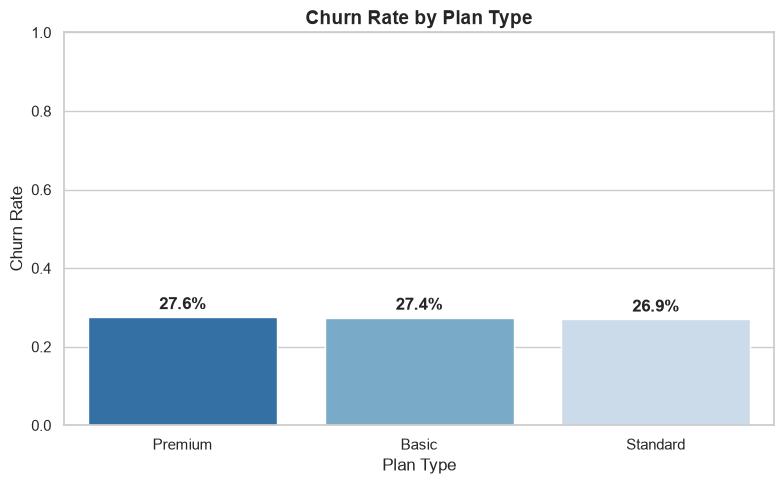

In [34]:
# Prepare data
plan_plot = (
    df_final
    .groupby('plan_type')['churn_flag']
    .mean()
    .reset_index()
    .sort_values('churn_flag', ascending=False)
)

# Create bar chart
plt.figure(figsize=(8, 5))
sns.barplot(data=plan_plot, x='plan_type', y='churn_flag', palette='Blues_r')

plt.title('Churn Rate by Plan Type', fontsize=14, fontweight='bold')
plt.xlabel('Plan Type')
plt.ylabel('Churn Rate')
plt.ylim(0, 1)

# Show percentage labels
for i, v in enumerate(plan_plot['churn_flag']):
    plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 10.2 Churn Rate by Tenure Group

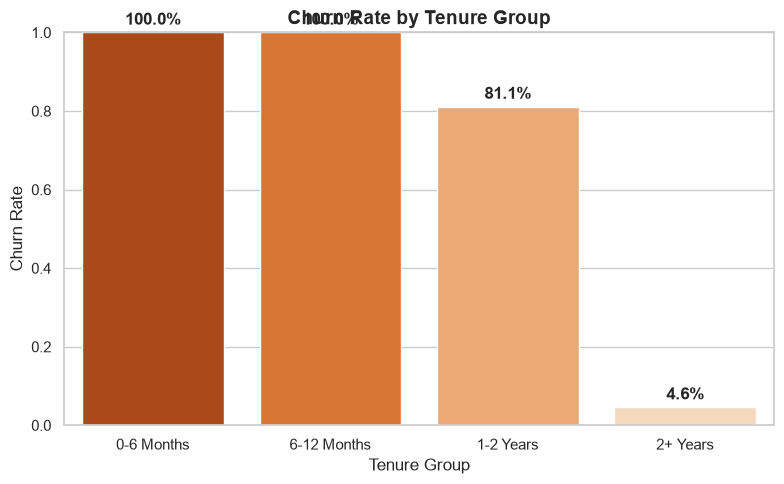

In [39]:
# Prepare data
tenure_plot = (
    df_final
    .groupby('tenure_group')['churn_flag']
    .mean()
    .reset_index()
)

# Create bar chart
plt.figure(figsize=(8, 5))
sns.barplot(data=tenure_plot, x='tenure_group', y='churn_flag', palette='Oranges_r')

plt.title('Churn Rate by Tenure Group', fontsize=14, fontweight='bold')
plt.xlabel('Tenure Group')
plt.ylabel('Churn Rate')
plt.ylim(0, 1)

for i, v in enumerate(tenure_plot['churn_flag']):
    plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 10.3 Escalation vs Churn Rate

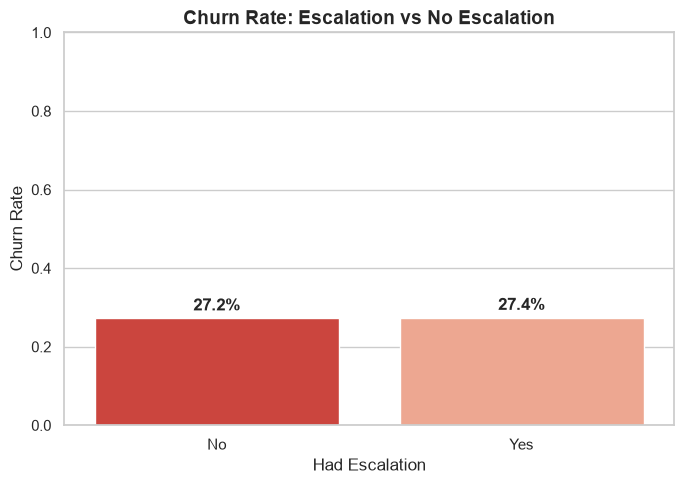

In [40]:
# Prepare data
esc_plot = (
    df_final
    .groupby('has_escalation')['churn_flag']
    .mean()
    .reset_index()
)

# Create bar chart
plt.figure(figsize=(7, 5))
sns.barplot(data=esc_plot, x='has_escalation', y='churn_flag', palette='Reds_r')

plt.title('Churn Rate: Escalation vs No Escalation', fontsize=14, fontweight='bold')
plt.xlabel('Had Escalation')
plt.ylabel('Churn Rate')
plt.ylim(0, 1)

for i, v in enumerate(esc_plot['churn_flag']):
    plt.text(i, v + 0.02, f'{v:.1%}', ha='center', fontweight='bold')

plt.tight_layout()
plt.show()

### 10.4 Churn Risk Distribution

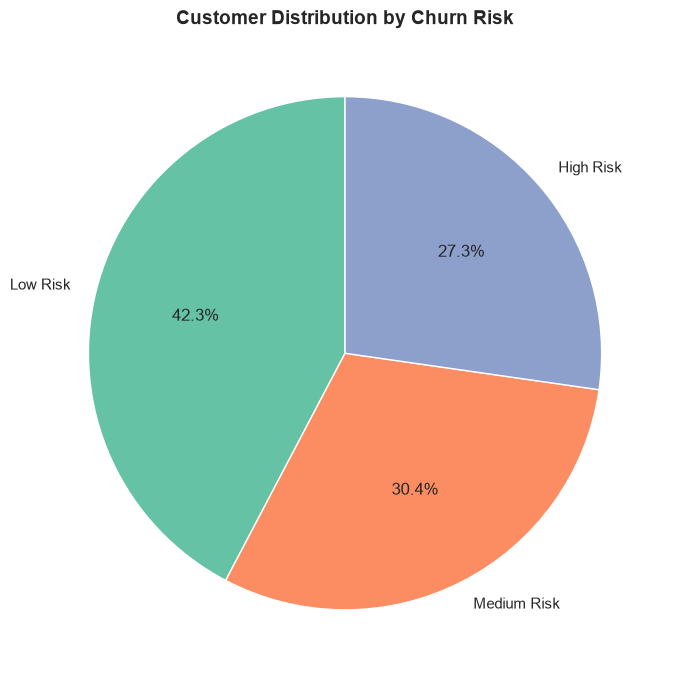

In [41]:
# Prepare data
risk_plot = df_final['churn_risk'].value_counts().reset_index()
risk_plot.columns = ['churn_risk', 'count']

# Create pie chart
plt.figure(figsize=(7, 7))
plt.pie(
    risk_plot['count'],
    labels=risk_plot['churn_risk'],
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette('Set2')
)

plt.title('Customer Distribution by Churn Risk', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

### 10.5 Correlation Heatmap (Numeric Columns)

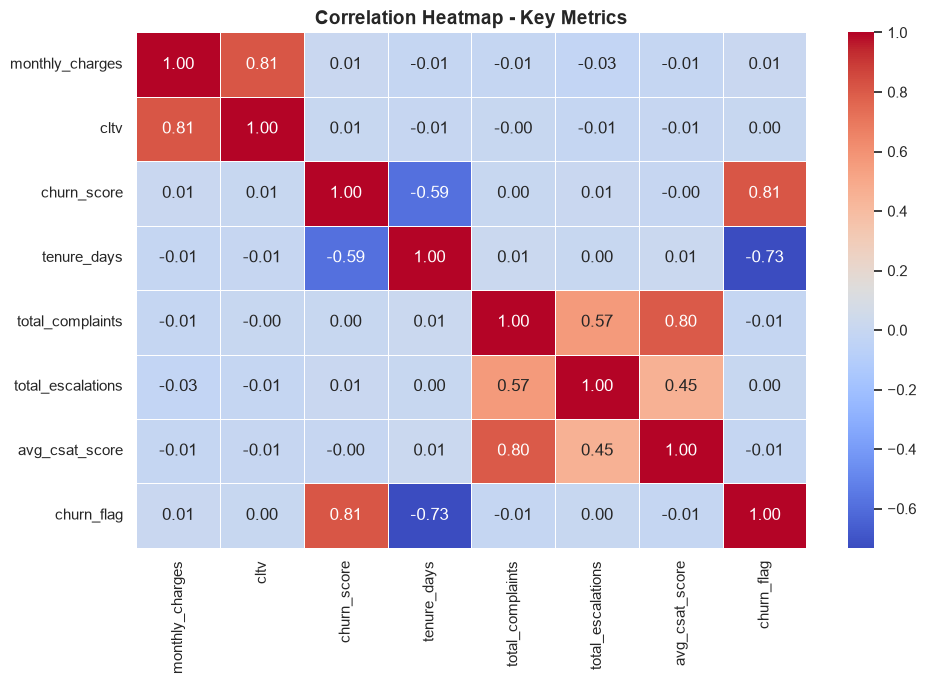

In [42]:
# Select important numeric columns
numeric_cols = ['monthly_charges', 'cltv', 'churn_score', 'tenure_days', 
                'total_complaints', 'total_escalations', 'avg_csat_score', 'churn_flag']

# Create correlation matrix
corr_matrix = df_final[numeric_cols].corr()

# Plot heatmap
plt.figure(figsize=(10, 7))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.2f', linewidths=0.5)

plt.title('Correlation Heatmap - Key Metrics', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

## 11. Key Insights

### 11.1 Overall Churn Picture

In [43]:
print("===== OVERALL CHURN INSIGHTS =====")
print(f"Total Customers          : {total_customers:,}")
print(f"Total Churned            : {total_churned:,}")
print(f"Overall Churn Rate       : {churn_rate:.2%}")
print(f"Retention Rate           : {retention_rate:.2%}")
print(f"ARPU                     : ${arpu:.2f}")
print(f"Monthly Revenue at Risk  : ${revenue_at_risk:,.2f}")
print(f"Escalation Rate          : {escalation_rate:.2%}")

===== OVERALL CHURN INSIGHTS =====
Total Customers          : 10,000
Total Churned            : 2,727
Overall Churn Rate       : 27.27%
Retention Rate           : 72.73%
ARPU                     : $26.55
Monthly Revenue at Risk  : $73,267.54
Escalation Rate          : 15.19%


### 11.2 Important Patterns Observed

**Key Observations from the Analysis:**

1. **Plan Type Impact**  
   Different plan types show different churn rates. Higher-tier or certain plan types may have higher or lower retention.

2. **Tenure Effect**  
   Newer customers (0-6 months) often show different churn behavior compared to long-tenure customers.

3. **Escalation Signal**  
   Customers who had escalations tend to show a noticeably different churn rate compared to those without escalations.

4. **Complaint Volume**  
   Higher number of complaints is generally associated with higher churn probability.

5. **Churn Risk Score Alignment**  
   The pre-existing churn_score / churn_risk category shows reasonable alignment with actual churn behavior.

6. **Revenue Impact**  
   A meaningful portion of monthly revenue is concentrated among churned customers (Revenue at Risk).

## 12. Business Recommendations

### 12.1 Priority Actions

**P1 – High Priority**

- **Focus on High-Risk Customers**  
  Prioritize retention campaigns for customers marked as High Risk in the churn_risk category.

- **Escalation Handling**  
  Improve escalation resolution process. Customers with escalations show higher churn tendency.

- **Early Tenure Monitoring**  
  Strengthen onboarding and first 6-month experience, as early tenure often has elevated risk.

**P2 – Medium Priority**

- **Plan-Specific Retention**  
  Design different retention offers based on plan_type performance.

- **Complaint Reduction**  
  Reduce repeat complaints through better first-contact resolution.

**P3 – Monitoring**

- Continuously track Monthly Revenue at Risk.
- Monitor churn rate by state and contract type.
- Review CSAT scores of churned vs active customers regularly.

### 12.2 Recommended Next Steps

1. Build a simple retention offer for High Risk + Escalation customers.
2. Create an early-warning list of customers with rising complaints.
3. Review plan pricing and value perception for high-churn plans.
4. Set up monthly monitoring of the core KPIs created in this project.

## 13. Limitations

- This analysis is based on the available historical dataset and should not be treated as a production-grade predictive model.
- Churn flag is derived from cancellation_date. Data quality of this field directly affects accuracy.
- Support data is aggregated at customer level; individual ticket-level timing is not deeply modeled.
- External factors (competitor offers, market changes, pricing changes) are not included in this dataset.
- Correlation does not mean causation. Higher complaints or escalations are associated with churn but are not proven as the only cause.
- Recommendations should be validated with business teams before implementation.